# Exercise 02 Workbook: your own protein

This notebook is **deliberately almost empty**, and it is entirely about **your** protein: the
one on your ex01 Character Sheet, which you carry through ex03, ex04 and your final project.

Its companion, **`ex02_guide.ipynb`**, works everything through on human p53 and PDB 3D08.
**Read the guide first**, then work here with it open beside you. The sections below carry the
same numbers as the guide's: A.1 to A.3, then B.1 to B.3.

## How to work in this notebook

- **Copy code from the guide and adapt it.** Its helpers work on any protein with an
  AlphaFold DB entry.
- **Structure the notebook however you like.** The sections are a checklist, not a template.
- **The reasoning is graded, not the code.** Every section asks for a written conclusion.
- **No GPU here.** B.1's AlphaFold 3 run happens in ColabFold's notebook, on
  Colab's free GPU.

**Time: about 45 to 60 minutes**, plus the wait for AlphaFold 3. **What you will not learn
here** is anything the guide did not show: every section asks for a guide step, repeated on
your protein.

## Using AI tools

You may use AI assistants for syntax, debugging and code snippets. You must supply the
predictions, the critical evaluation and the biological reasoning. **"The AI said so" is not
an answer.**

**Predict-first prompts** (A.1 and B.1) ask for your prediction *before* you run
anything. That written prediction is the graded artefact. Being wrong costs nothing; not
predicting costs the marks.

## Setup

Copy the guide's setup cell here and run it first. A Colab notebook starts empty, so
nothing from the guide's session carries over here.

In [2]:
#@title Setup {display-mode: "form"}
# Setup. Everything in this notebook runs on a plain CPU runtime.
try:
    from google.colab import drive  # noqa: F401  (import is the availability test)

    is_google_colab = True
except ImportError:
    is_google_colab = False

if is_google_colab:
    %pip install numpy==2.1.3 pandas==2.2.3 matplotlib==3.10.0 py3dmol==2.4.0 mdanalysis==2.10.0 biopython==1.85 rdkit==2026.3.5

import warnings

warnings.filterwarnings("ignore")

import json
import os
import re
import tempfile
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
import pandas as pd
import py3Dmol
import requests
from Bio.PDB import PDBIO, MMCIFParser
from MDAnalysis.analysis import align, distances
from rdkit import Chem
from rdkit.Chem import rdMolAlign

print("Libraries loaded -- no GPU needed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 92.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 111.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.5 MB/s eta 0:00:00


Libraries loaded -- no GPU needed


---

## Your structure: the crystal from ex01

This notebook works on **the crystal you chose in ex01**, the PDB entry on your Character
Sheet, and on no other: not another entry of the same protein, even a sharper one. The
residue numbers you carry from one exercise to the next belong to that entry. Every
candidate numbers its residues the way UniProt does, so they also line up with both AlphaFold models, as long as B.1 gets your whole
UniProt sequence.

Put its PDB ID at the top of your first code cell, as `PDB_ID = "..."`, and use `PDB_ID`
wherever the guide names its own entry.

In [3]:
PDB_ID = "1A9T"
CHAIN  = "A"
LIGAND = "R1P"

---

# Part A: Your protein's AlphaFold prediction

## A.1 Predict first, before you fetch anything

**Before you look at any number**, predict: will confidence be uniform or split, and where?
Base it on your ex01 findings: the residues your crystal failed to resolve, and those with the
highest B-factors. A wrong prediction with stated reasoning earns full marks; "I don't know"
earns none.

Protein missing from [the AlphaFold Database](https://alphafold.ebi.ac.uk/)? Use the
[AlphaFold Server](https://alphafoldserver.com/welcome) or
[ColabFold](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/AlphaFold2.ipynb).

> **My prediction:**
>The core will have high confidence. The two ends will have the lowest confidence and the loop 248–256, an the other flexible stretches will have lower confidence (1-4, 40-41, 183-185, 248-256, 258-259, 264-273, 279-284).

> **My reasoning (citing my ex01 findings):**
the with resudue 285-289 were never modeled before so confidence for that should be low. The core(b-sheet and helices) the predictor should have plenty of evidence to predict well. The loop form 248-256 should have a lower confidence has it had the highest b-values in ex01. The same reasoning applys to the other felxible stretches.

In [4]:
def prediction_record(uniprot: str, fragment: int = 1) -> pd.Series:
    """AlphaFold DB's record for one UniProt accession, as a single row.

    The record carries the summary metrics and the URLs of every other file, so nothing
    below ever builds an AlphaFold DB URL by hand. Very long proteins come back as more
    than one fragment; most, including p53, fit in `F1`.
    """
    entries = pd.json_normalize(
        requests.get(f"https://alphafold.ebi.ac.uk/api/prediction/{uniprot}").json()
    )
    return entries.set_index("modelEntityId").loc[f"AF-{uniprot}-F{fragment}"]


def download_prediction_files(entry: pd.Series, directory: Path) -> dict[str, Path]:
    """Save the three files the record points at. Returns {name: path}.

    A URL the database does not serve is reported and skipped rather than stopping the
    download of the others.
    """
    directory.mkdir(exist_ok=True)
    wanted = {"model.pdb": "pdbUrl", "confidence.json": "plddtDocUrl", "pae.json": "paeDocUrl"}
    saved = {}
    for name, field in wanted.items():
        response = requests.get(entry[field])
        target = directory / f"{entry.name}-{name}"
        if response.status_code != 200:
            print(f"    {name:<18} HTTP {response.status_code}  <-- unavailable, skipped")
            continue
        target.write_bytes(response.content)
        saved[name] = target
        print(f"    {name:<18} {len(response.content):>9,} bytes  -> {target}")
    return saved


def per_residue_confidence(entry: pd.Series) -> pd.DataFrame:
    """PLDDT and its confidence category, indexed by residue number.

    The file is three parallel arrays, which is already a table. Indexing by residue
    number means slicing a range later reads like the biology.
    """
    return (
        pd.read_json(entry["plddtDocUrl"])
        .rename(columns={"confidenceScore": "pLDDT", "confidenceCategory": "category"})
        .set_index("residueNumber")
    )


def pae_matrix(entry: pd.Series) -> pd.DataFrame:
    """The n x n predicted aligned error, indexed by residue number on both axes."""
    record = pd.read_json(entry["paeDocUrl"]).iloc[0]
    pae = pd.DataFrame(record["predicted_aligned_error"])
    pae.index += 1              # residue numbering starts at 1, not 0
    pae.columns += 1
    return pae


def confidence_bands(entry: pd.Series) -> pd.Series:
    """The four fractionPlddt* bands, as a Series labelled by their pLDDT range."""
    labels = {
        "fractionPlddtVeryLow": "Very low (<50)",
        "fractionPlddtLow": "Low (50-70)",
        "fractionPlddtConfident": "Confident (70-90)",
        "fractionPlddtVeryHigh": "Very high (>90)",
    }
    return pd.Series({label: entry[field] for field, label in labels.items()})


## A.2 Confidence analysis

Produce, for your protein: the global mean pLDDT, a per-residue **pLDDT plot**, a **PAE
heatmap** and the four `fractionPlddt*` bands.

**Then answer:**

- Where is pLDDT above 90, and where below 70? Why there: core, surface, loops, termini?
- Which parts does the PAE place confidently relative to each other, and which not?
- Is your protein uniformly mediocre, or excellent in one region and uncertain elsewhere?
- How did your A.1 prediction hold up? If it was wrong, what did you miss?

In [17]:
UNIPROT = "P55859"          # our protein
DATA = Path("afdb_data")
DATA.mkdir(exist_ok=True)

entry = prediction_record(uniprot=UNIPROT)
(DATA / f"afdb_{UNIPROT}.json").write_text(entry.to_json(indent=2))

print(f"Model: {entry.name}  (pipeline: {entry['toolUsed']})")
print(f"Sequence length: {entry['sequenceEnd'] - entry['sequenceStart'] + 1} residues")
print(f"Global mean pLDDT: {entry['globalMetricValue']:.1f}\n")

print("  provenance, and the fields used below:")
for key in ("modelCreatedDate", "latestVersion", "uniprotSequence", "globalMetricValue",
            "pdbUrl", "plddtDocUrl", "paeDocUrl"):
    if key in entry:
        value = entry[key]
        shown = f"{value[:52]}..." if isinstance(value, str) and len(value) > 55 else value
        print(f"    {key:<20} {shown}")

print("\n  downloading:")
files = download_prediction_files(entry=entry, directory=DATA)

Model: AF-P55859-F1  (pipeline: AlphaFold Monomer v2.0 pipeline)
Sequence length: 289 residues
Global mean pLDDT: 94.0

  provenance, and the fields used below:
    modelCreatedDate     2025-08-01T00:00:00Z
    latestVersion        6
    uniprotSequence      MANGYTYEDYQDTAKWLLSHTEQRPQVAVICGSGLGGLVNKLTQAQTFDYSE...
    globalMetricValue    94.0
    pdbUrl               https://alphafold.ebi.ac.uk/files/AF-P55859-F1-model...
    plddtDocUrl          https://alphafold.ebi.ac.uk/files/AF-P55859-F1-confi...
    paeDocUrl            https://alphafold.ebi.ac.uk/files/AF-P55859-F1-predi...

  downloading:
    model.pdb            188,162 bytes  -> afdb_data/AF-P55859-F1-model.pdb
    confidence.json        3,971 bytes  -> afdb_data/AF-P55859-F1-confidence.json
    pae.json             172,952 bytes  -> afdb_data/AF-P55859-F1-pae.json


In [18]:
def plot_plddt(confidence: pd.DataFrame, highlight: tuple[int, int] | None = None,
               title: str | None = None, ax: plt.Axes | None = None,
               label: str = "AlphaFold DB") -> plt.Axes:
    """PLDDT along the sequence. `highlight` shades a (start, end) residue range."""
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 4))
    ax.plot(confidence.index, confidence["pLDDT"], color="tab:blue", lw=1, label=label)
    ax.axhline(90, color="grey", ls=":", lw=1, label="pLDDT = 90 (very high)")
    ax.axhline(70, color="grey", ls="--", lw=1, label="pLDDT = 70 (confident cutoff)")
    if highlight is not None:
        ax.axvspan(highlight[0], highlight[1], color="tab:green", alpha=0.15,
                   label=f"resolved range ({highlight[0]}-{highlight[1]})")
    ax.set_xlabel("Residue number")
    ax.set_ylabel("pLDDT")
    ax.set_ylim(0, 100)
    ax.set_title(title or "AlphaFold DB per-residue confidence")
    ax.legend(loc="lower center")
    return ax


def plot_pae(pae: pd.DataFrame | np.ndarray,
             title: str = "Predicted Aligned Error (PAE)",
             ax: plt.Axes | None = None) -> plt.Axes:
    """The PAE matrix as a heatmap, dark = confident.

    Row i, column j is the error at residue j when the structures are aligned on residue
    i. Takes the DataFrame from `pae_matrix` or a plain array, such as AlphaFold 3's `pae`.
    """
    values = np.asarray(pae)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(values, cmap="Greens_r", vmin=0, vmax=values.max(),
                   extent=[1, values.shape[1], values.shape[0], 1])
    ax.set_xlabel("Scored residue")
    ax.set_ylabel("Aligned residue")
    ax.set_title(title)
    ax.figure.colorbar(im, ax=ax, label="Expected error (A)")
    return ax


In [25]:
confidence = per_residue_confidence(entry=entry)

print(confidence.loc[270:289].to_string())

# 1-4, 40-41, 183-185, 248-256, 258-259, 264-273, 279-284 these are the regions with a high b-factor where we suspected the confidence to be lower
# this is just a sanity check to pinpoint exactly where the drops in confidence are in the plot below.
print(confidence.loc[30:50].to_string())
print(confidence.loc[240:280].to_string())

               pLDDT category
residueNumber                
270            90.75        H
271            90.25        H
272            89.44        M
273            90.75        H
274            92.50        H
275            92.12        H
276            90.75        H
277            90.56        H
278            88.94        M
279            88.44        M
280            85.38        M
281            84.19        M
282            81.00        M
283            73.88        M
284            67.25        L
285            62.38        L
286            50.22        L
287            41.84        D
288            36.94        D
289            31.47        D
               pLDDT category
residueNumber                
30             98.00        H
31             95.56        H
32             90.44        H
33             87.25        M
34             80.19        M
35             85.06        M
36             86.31        M
37             87.12        M
38             86.88        M
39        

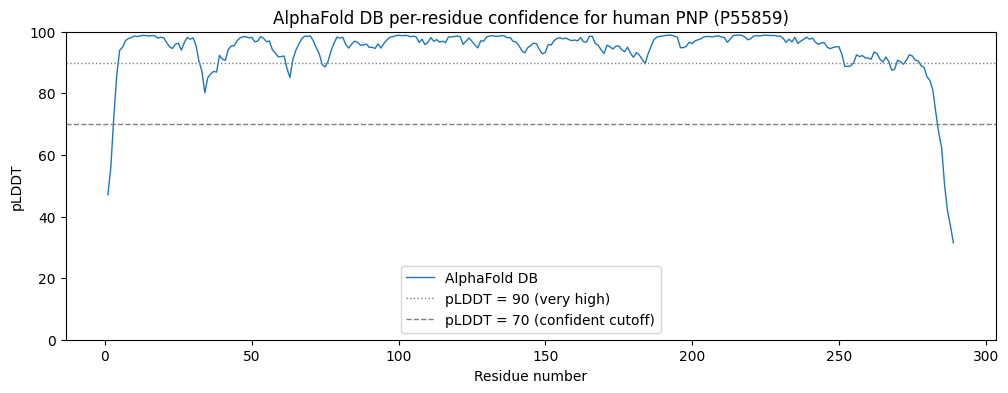

In [23]:
plot_plddt(confidence=confidence,
           title=f"AlphaFold DB per-residue confidence for human PNP ({UNIPROT})")
plt.show()

PAE matrix: 289 x 289 residues
Largest expected error in this entry: 30.0 A


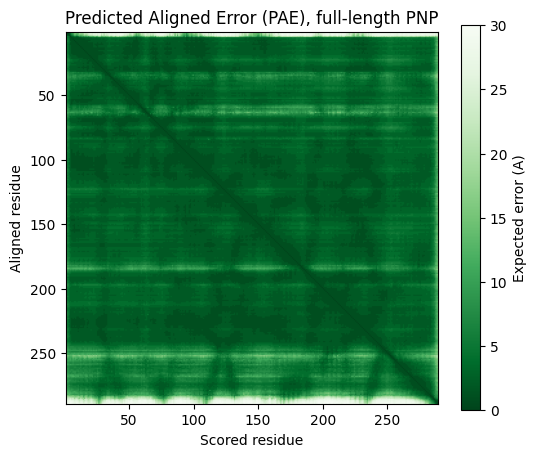

In [21]:
pae = pae_matrix(entry=entry)
print(f"PAE matrix: {pae.shape[0]} x {pae.shape[1]} residues")
print(f"Largest expected error in this entry: {pae.values.max():.1f} A")

plot_pae(pae=pae, title="Predicted Aligned Error (PAE), full-length PNP")
plt.show()

In [26]:
bands = confidence_bands(entry=entry)

print(f"Mean pLDDT {entry['globalMetricValue']:.1f} is made of:")
for label, fraction in bands.items():
    print(f"  {label:<20} {fraction*100:5.1f}%  {'#' * int(fraction * 50)}")

usable = bands["Confident (70-90)"] + bands["Very high (>90)"]
print(f"\n  above 70 (usable): {usable*100:.1f}%")
print(f"  below 70         : {(1 - usable)*100:.1f}%")

Mean pLDDT 94.0 is made of:
  Very low (<50)         1.4%  
  Low (50-70)            1.4%  
  Confident (70-90)      9.0%  ####
  Very high (>90)       88.2%  ############################################

  above 70 (usable): 97.2%
  below 70         : 2.8%


### A.2 Confidence Analysis Results

* **Global Mean pLDDT**: `94.0` (Excellent structure overall)
* **Confidence Bands (pLDDT Composition)**:
  * **Very high (>90)**: `88.2%`
  * **Confident (70-90)**: `9.0%`
  * **Low (50-70)**: `1.4%`
  * **Very low (<50)**: `1.4%`
  * **Usable residues (above 70)**: `97.2%`

* **pLDDT Plot Findings**:
  * Extremely high confidence (pLDDT > 90) across almost the entire sequence, including the core structured regions.
  * Dips in confidence can be observed at the N-terminus (residues 1-2, where residue 1 is at 47.09) and the C-terminus (starting around residue 284, dropping rapidly to 31.47 at residue 289).
  * The loop at residue 246-256 has a drop in confidence but doesnt drop below 80 so alphafold is still confident in its prediction
  * There is a notable dip around residue 33-35 (pLDDT ~80) and smaller local fluctuations around residues 62-65 and 183-185.

Our prediciton for the confidence was kind of right: The region where we expected low confidence were correct but apparently not big enough to cause a proper drop confidence as, except for three regions and the ends the confidence of the model is still confident and doesnt hurt the global mean pLDDT.

* **PAE Heatmap Findings**:
  * Most of the matrix is colored deep green (low expected aligned error), indicating that the relative positions of almost all domains are predicted with high confidence.
  * Slight light-green lines (higher relative error) correspond to the flexible loop regions and termini, showing that while they are locally structured, their relative positioning has minor uncertainty.

## A.3 The AlphaFold model against your crystal

Superimpose the AlphaFold DB model on your ex01 crystal (`PDB_ID`) as the guide does. Report the
overall Cα RMSD, over how many matched residues, and the highest-deviation regions.

**Then answer:** why do those regions differ? An unresolved crystal loop nearby, a mutation, a
bound ligand or ion the model lacks, or a genuinely wrong prediction?

If your protein has no AlphaFold DB entry, **say so** rather than forcing the comparison. That
is a real outcome, not a failure.

In [27]:
def fetch_pdb(pdb_id: str, path: str | None = None) -> str:
    """Download one PDB entry next to the notebook, once. Returns the local path.

    Fetched with Python rather than wget, so this works identically on Colab, in a local
    conda environment, and in a container: the download is not a Colab-only step.
    MDAnalysis reads structures but does not retrieve them, so this stays plain urllib.
    """
    path = path or f"{pdb_id}.pdb"
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"https://files.rcsb.org/download/{pdb_id}.pdb", path)
        print(f"Downloaded {path} from RCSB")
    else:
        print(f"{path} already present")
    return path


def read_structure(path: str | Path) -> mda.AtomGroup:
    """A PDB or mmCIF file as MDAnalysis atoms, one conformation per atom.

    MDAnalysis reads PDB but not mmCIF, so an mmCIF file, such as AlphaFold 3's model, is
    first rewritten as PDB beside it. Chain and residue numbers are the author ones, which
    for AlphaFold 3 count along the sequence you pasted. Where a crystal models an atom in
    alternate positions, only position A is kept: left in, that atom would count twice.
    Atoms with no alternates leave the field blank, and `not altloc ?` is how to say so.
    """
    path = Path(path)
    if path.suffix == ".cif":
        writer = PDBIO()
        writer.set_structure(MMCIFParser(QUIET=True).get_structure(path.stem, path))
        path = path.with_suffix(".pdb")
        writer.save(str(path))
    return mda.Universe(path).select_atoms("altloc A or not altloc ?")


def superpose(mobile: mda.AtomGroup, reference: mda.AtomGroup,
              chain: str = "A") -> tuple[float, pd.Series]:
    """Move `mobile` onto `reference`. Returns the CA RMSD and each residue's deviation.

    The fit uses the CA atoms of the residues both structures have: it is the rotation and
    shift that make their RMSD smallest, and that RMSD is the root mean square of the
    per-residue deviation returned beside it. Every atom of `mobile` moves with the fit,
    ligands included, so the two structures can then be measured and viewed in one frame.

    Matching is by residue NUMBER, not by list position: a crystal with unresolved loops
    is not a gap-free span, and pairing by position would silently misalign everything
    after the first gap.
    """
    ca = f"protein and name CA and chainID {chain}"
    shared = sorted(set(mobile.select_atoms(ca).resids)
                    & set(reference.select_atoms(ca).resids))
    pairs = f"{ca} and resid {' '.join(map(str, shared))}"
    _, rmsd = align.alignto(mobile, reference, select=pairs)     # RMSD before, and after
    moved, fixed = mobile.select_atoms(pairs), reference.select_atoms(pairs)
    deviation = pd.Series(distances.dist(moved, fixed)[2],       # atom-by-atom distances
                          index=pd.Index(fixed.resids, name="residue_number"),
                          name="deviation (A)")
    return float(rmsd), deviation


def pdb_text(atoms: mda.AtomGroup) -> str:
    """The atoms as PDB text: what py3Dmol and RDKit read, where MDAnalysis holds objects."""
    with tempfile.NamedTemporaryFile(suffix=".pdb") as handle:
        atoms.write(handle.name, bonds=None)
        return Path(handle.name).read_text()


def show_superposition(reference: mda.AtomGroup, mobile: mda.AtomGroup,
                       highlight: list[int] | tuple[int, ...] = (),
                       ligand: str | None = None, width: int = 900,
                       height: int = 550) -> py3Dmol.view:
    """A crystal and an AlphaFold model in one view: `highlight` as sticks, `ligand` as spheres.

    `reference`, the crystal, is neon green. `mobile`, the model, takes AlphaFold's own
    confidence colours, atom by atom, from the pLDDT in its B-factor column: dark blue
    above 90, light blue from 70, yellow from 50, orange below.
    """
    view = py3Dmol.view(width=width, height=height)
    for atoms in (reference, mobile):
        view.addModel(pdb_text(atoms=atoms), "pdb")

    colored = [({"model": 0}, "#39FF14")]
    for low, high, color in ((90, 101, "#0053D6"), (70, 90, "#65CBF3"),
                             (50, 70, "#FFDB13"), (0, 50, "#FF7D45")):
        in_band = (mobile.tempfactors >= low) & (mobile.tempfactors < high)
        if in_band.any():
            # The PDB text numbers its atoms 1, 2, 3, ... in the order they sit in `mobile`.
            serials = (np.flatnonzero(in_band) + 1).tolist()
            colored.append(({"model": 1, "serial": serials}, color))

    for atoms, color in colored:
        view.setStyle(atoms, {"cartoon": {"color": color}})
        if len(highlight):
            view.addStyle({**atoms, "resi": list(highlight)}, {"stick": {"color": color}})
        if ligand:
            view.addStyle({**atoms, "resn": ligand},
                          {"sphere": {"color": color, "radius": 0.6}})
    view.zoomTo({"model": 0, "resi": list(highlight)} if len(highlight) else {})
    return view

In [28]:
# AlphaFold's model is already on disk from the download above; the crystal is one call.
af_model = read_structure(path=files["model.pdb"])
crystal = read_structure(path=fetch_pdb(pdb_id=PDB_ID, path=f"{DATA}/{PDB_ID}.pdb"))

af_ca = af_model.select_atoms("protein and name CA").resids
crystal_ca = crystal.select_atoms("protein and name CA and chainID A").resids
print(f"AlphaFold model: {len(af_ca)} CA atoms, range {af_ca.min()}-{af_ca.max()}")
print(f"{PDB_ID} crystal: {len(crystal_ca)} CA atoms, range {crystal_ca.min()}-{crystal_ca.max()}")

unresolved = sorted(set(range(crystal_ca.min(), crystal_ca.max() + 1)) - set(crystal_ca.tolist()))
print(f"Matched (by residue number) residues: {len(set(af_ca) & set(crystal_ca))}")
print(f"Residues with no crystal coordinates inside that range (unresolved loops): {unresolved}")

Downloaded afdb_data/1A9T.pdb from RCSB
AlphaFold model: 289 CA atoms, range 1-289
1A9T crystal: 284 CA atoms, range 1-284
Matched (by residue number) residues: 284
Residues with no crystal coordinates inside that range (unresolved loops): []


In [31]:
# Superpose the AlphaFold model on the crystal, then read the deviation residue by
# residue: the overall number hides where the disagreement actually is.
overall_rmsd, deviation = superpose(mobile=af_model, reference=crystal)

print(f"Overall CA RMSD over {len(deviation)} matched residues: {overall_rmsd:.2f} Å")

print("\nHighest-deviation residues:")
display(deviation.nlargest(20).round(2))

# Update the positions below with the actual mutations or active site residues of interest for your protein!
# For human PNP (1A9T), let's inspect the active site or any substituted residue if applicable.
# (Change the tuple below to match your Character Sheet residues if they have substitutions)
print("\nDeviation at key residues of interest:")
for position, label in ((64, "Active Site His64"), (243, "Active Site His243"), (201, "Glu201")):
    print(f"  {label} (Residue {position}): {deviation.get(position, float('nan')):.2f} Å")

Overall CA RMSD over 284 matched residues: 0.70 Å

Highest-deviation residues:


,deviation (A)
residue_number,
2,6.60
3,5.44
1,3.28
281,2.41
252,2.20
251,2.18
4,1.42
253,1.16
58,0.89



Deviation at key residues of interest:
  Active Site His64 (Residue 64): 0.37 Å
  Active Site His243 (Residue 243): 0.46 Å
  Glu201 (Residue 201): 0.76 Å


**worked answer:** The overall ca RMSD is 0.7 Å. So the fold level prediciton is quite close the observed chrystall.

** Disagreement**: The highest diagreement is beginning and end which was expected. Also residues in the loop (246-256) show higher diagreement which is in line with the results above and the b-factor observed in ex01

---

# Part B: AlphaFold 3, with your ligand

## B.1 Predict, then run AlphaFold 3

**Before you run anything**, predict: where will AlphaFold 3 put your ex01 ligand, and how
sure will it be? Base it on your ex01 contact residues and your A.3 deviations near them.

Then run AlphaFold 3 in ColabFold's notebook as the guide's B.1 does, with your whole UniProt
sequence and your ligand's CCD code.

> **My prediction:**
>AlphaFold 3 will place R1P in the same pocket as the crystal, held by the same contact residues. I expect the pose to be close to the crystal one (ligand RMSD under about 1.5 Å), with the phosphate and the middle of the site placed most accurately. The 5'-hydroxyl end of the ribose, next to HIS257 and VAL260, may be slightly off, and I expect the ligand's confidence to be high but not uniform, with the weakest part near that edge.

> **My reasoning (citing my ex01 contacts and A.3):**
In A.3 the protein model matched the crystal to 0.70 Å over 284 residues, and the pocket residues we could check deviate by less than 1 Å (HIS64 0.37 Å, PHE200 0.65 Å, GLU201 0.76 Å). So AlphaFold builds the pocket in the right shape, and a ligand placed into it should end up where the crystal R1P is. In ex01, nine of the 13 contacts were very rigid and six of 13 are conserved, which gives strong evidence for the site. The weaker spot is the edge next to the loop 248–256. That loop deviates by about 2 Å in A.3 (251–253) and had B-factors up to 55 Å² in ex01. HIS257 and VAL260 lie directly after it and were the most mobile R1P contacts, so any small error in the pocket shape would show up at the 5'-hydroxyl first.

In [32]:
# The exact string for ColabFold's `protein` box: the whole UniProt sequence, which the
# AlphaFold DB record already carries, on one line so that it pastes cleanly.
print(f"{UNIPROT}, {len(entry['uniprotSequence'])} residues -- copy the line below:\n")
print(entry["uniprotSequence"])

P55859, 289 residues -- copy the line below:

MANGYTYEDYQDTAKWLLSHTEQRPQVAVICGSGLGGLVNKLTQAQTFDYSEIPNFPESTVPGHAGRLVFGILNGRACVMMQGRFHMYEGYPFWKVTFPVRVFRLLGVETLVVTNAAGGLNPNFEVGDIMLIRDHINLPGFSGENPLRGPNEERFGVRFPAMSDAYDRDMRQKAHSTWKQMGEQRELQEGTYVMLGGPNFETVAECRLLRNLGADAVGMSTVPEVIVARHCGLRVFGFSLITNKVIMDYESQGKANHEEVLEAGKQAAQKLEQFVSLLMASIPVSGHTG


## B.2 What AlphaFold 3 returns

Upload your ZIP and unpack it as the guide does. Report `ranking_score`, `ptm`, the
protein-ligand `chain_pair_iptm` and `chain_pair_pae_min`, your ligand's mean pLDDT, and
AlphaFold 3's per-residue pLDDT drawn over your A.2 curve.

**Then answer:** which of these numbers is about your ligand, and what does each say? Where
do the two pLDDT curves part, and why might they?

In [33]:
def unpack_af3_result(zip_path: Path, directory: Path) -> dict[str, Path]:
    """Unzip an AlphaFold 3 result and find the top-ranked sample's three files.

    Every sample has a folder of its own, and the top-ranked one is copied to the top
    level, which is the shallowest match. ColabFold names the files `<job>_model.cif` and
    so on, the AlphaFold Server `fold_<job>_model_0.cif`: both are found.
    """
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(directory)
    patterns = {
        "model": r"_model(_0)?\.cif$",
        "summary": r"_summary_confidences(_0)?\.json$",
        "confidences": r"(?<!summary)_confidences\.json$|_full_data_0\.json$",
    }
    found = {}
    for name, pattern in patterns.items():
        matches = [path for path in directory.rglob("*") if re.search(pattern, path.name)]
        if not matches:
            raise FileNotFoundError(f"no {name} file in {zip_path}: not an AlphaFold 3 ZIP?")
        found[name] = min(matches, key=lambda path: (len(path.parts), path.name))
    return found


def residue_plddt(structure: mda.AtomGroup, chain: str = "A") -> pd.Series:
    """Per-residue pLDDT for one chain: the B-factor column, averaged over each residue.

    An AlphaFold DB model gives every atom of a residue the same value, so this is its
    pLDDT exactly; AlphaFold 3 scores each atom, so here it is their mean.
    """
    atoms = structure.select_atoms(f"protein and chainID {chain}")
    return pd.Series(atoms.tempfactors).groupby(atoms.resids).mean()

In [35]:
# The run made with B.1's inputs ships with this exercise as a ZIP: read from disk when
# this notebook sits beside it, otherwise downloaded once from the exercise repository.
AF3_ZIP = Path("pnp_zn_alphafold3_31eb402bba.result.zip")
if not AF3_ZIP.exists():
    response = requests.get("https://raw.githubusercontent.com/Michel-99/"
                            f"my-repo/main/{AF3_ZIP.name}")
    response.raise_for_status()
    AF3_ZIP.write_bytes(response.content)

af3_files = unpack_af3_result(zip_path=AF3_ZIP, directory=Path("af3_p53_zn"))
summary = json.loads(af3_files["summary"].read_text())
af3_confidences = json.loads(af3_files["confidences"].read_text())

print("Whole model:")
for key in ("ranking_score", "ptm", "iptm", "fraction_disordered", "has_clash"):
    print(f"  {key:<22} {summary[key]}")
print("Protein (chain A) with zinc (chain B):")
print(f"  {'chain_pair_iptm':<22} {summary['chain_pair_iptm'][0][1]}")
print(f"  {'chain_pair_pae_min':<22} {summary['chain_pair_pae_min'][0][1]} Å")

Whole model:
  ranking_score          0.89
  ptm                    0.86
  iptm                   0.9
  fraction_disordered    0.0
  has_clash              0.0
Protein (chain A) with zinc (chain B):
  chain_pair_iptm        0.9
  chain_pair_pae_min     2.29 Å


B-factor column equals atom_plddts: True
Mean pLDDT over 3D08's range 97-287: AlphaFold 2 94.8, AlphaFold 3 87.2
pLDDT of the zinc: 78.2


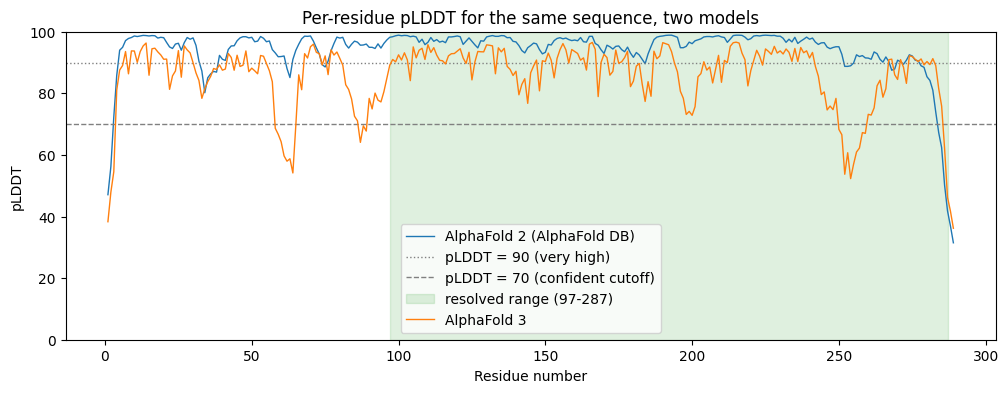

In [36]:
af3_model = read_structure(path=af3_files["model"])
af3_zn = af3_model.select_atoms("resname ZN")
af3_plddt = residue_plddt(structure=af3_model)

# The B-factor column really is the atom pLDDT: checked against the JSON, atom by atom.
print("B-factor column equals atom_plddts:",
      np.allclose(af3_model.tempfactors, af3_confidences["atom_plddts"], atol=0.01))
print(f"Mean pLDDT over 3D08's range {CRYSTAL_START}-{CRYSTAL_END}: "
      f"AlphaFold 2 {core.mean():.1f}, "
      f"AlphaFold 3 {af3_plddt.loc[CRYSTAL_START:CRYSTAL_END].mean():.1f}")
print(f"pLDDT of the zinc: {af3_zn.tempfactors.mean():.1f}")

ax = plot_plddt(confidence=confidence, highlight=(CRYSTAL_START, CRYSTAL_END),
                label="AlphaFold 2 (AlphaFold DB)",
                title="Per-residue pLDDT for the same sequence, two models")
ax.plot(af3_plddt.index, af3_plddt.values, color="tab:orange", lw=1, label="AlphaFold 3")
ax.legend(loc="lower center")
plt.show()

In [39]:

CRYSTAL_START = 1
CRYSTAL_END = 284

print(f"Updated crystal limits for PNP: residues {CRYSTAL_START} to {CRYSTAL_END}")

Updated crystal limits for PNP: residues 1 to 284


Mean pLDDT over PNP's range 1-284:
  AlphaFold 2: 94.9
  AlphaFold 3: 86.3


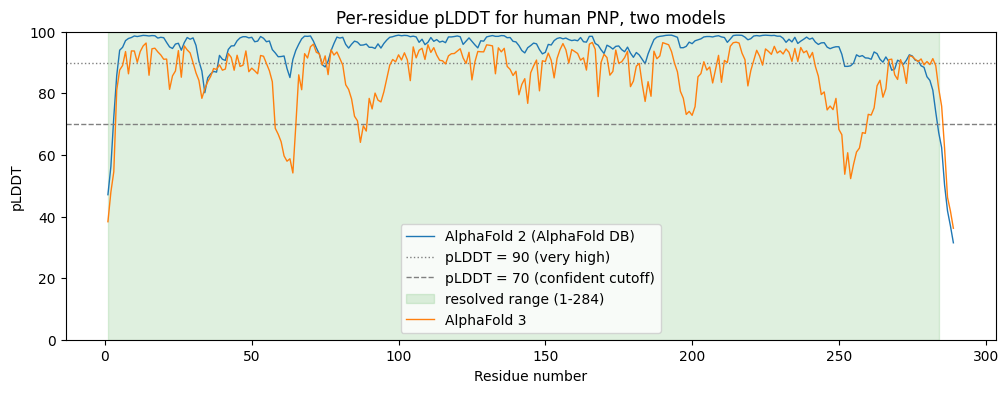

In [40]:
# Let's re-run the comparison plot with the correct PNP crystal limits highlighted!
print(f"Mean pLDDT over PNP's range {CRYSTAL_START}-{CRYSTAL_END}:")
print(f"  AlphaFold 2: {confidence.loc[CRYSTAL_START:CRYSTAL_END]['pLDDT'].mean():.1f}")
print(f"  AlphaFold 3: {af3_plddt.loc[CRYSTAL_START:CRYSTAL_END].mean():.1f}")

ax = plot_plddt(confidence=confidence, highlight=(CRYSTAL_START, CRYSTAL_END),
                label="AlphaFold 2 (AlphaFold DB)",
                title="Per-residue pLDDT for human PNP, two models")
ax.plot(af3_plddt.index, af3_plddt.values, color="tab:orange", lw=1, label="AlphaFold 3")
ax.legend(loc="lower center")
plt.show()

## B.3 Your ligand against your crystal

Superpose the AlphaFold 3 model on your crystal (`PDB_ID`) as the guide's B.3 does. Report
the Cα RMSD, your ligand's RMSD against the crystal pose with how many atoms matched, and the
residues within 4 Å of each pose, as in ex01.

**Then answer:** was your B.1 prediction right? AlphaFold 3 trained on PDB entries released
before 30 September 2021: was yours one? Would a small ligand RMSD prove that your ligand
binds there? What would?

---

## Before you submit

- [ ] A.1 prediction **written before** the analysis in A.2, citing your ex01 findings
- [ ] pLDDT plot, PAE heatmap and confidence **composition** for your own protein
- [ ] A.3 comparison done, **or** explicitly explained why it could not be
- [ ] B.1 prediction **written before** your AlphaFold 3 run
- [ ] B.2 AlphaFold 3's confidence reported, with the numbers that concern your ligand
- [ ] B.3 ligand RMSD against your crystal, with the residues around both poses
- [ ] Anything that did not work is **described honestly** rather than deleted: a documented
      dead end earns marks, a silently missing section does not